# 23 · Faults, repairs, and replay

Can a perfectly shaped forecast still be in the wrong units? First inject simple output faults, then implement and repair a missing inverse transform. Plot the consequences, check the model's promised shift property, and replay the saved evidence.

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally. A temporary report file is removed after use.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from timegym import Forecast, Pipeline, Scenario, NaiveForecaster, GaussianAR1Forecaster
from timegym.checks import check_shift_equivariance
from timegym.diagnostics import evaluate_forecast
from timegym.mutations import mutate_forecast
from timegym.provenance import replay_case

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

def diagnostics_table(result):
    return pd.DataFrame([{'check': d.name, 'status': d.status,
                          'category': d.category, 'message': d.message}
                         for d in result.diagnostics])


## Start from a known-law fixture

The reference knows generator parameters and supplies a clean evaluator fixture, not a learned competitor. A contract `PASS` concerns that check only; capability without a declared tolerance is `INCONCLUSIVE`, absent inputs are `UNSUPPORTED`, and execution exceptions are `ERROR`.

In [2]:
scenario = Scenario('white_noise', context_length=120, horizon=12,
                    parameters={'mean': 50.0, 'sigma': 2.0})
case = scenario.generate(seed=7)
reference_fixture = case.reference.forecast(n_samples=128, seed=19)
clean_result = evaluate_forecast(case, reference_fixture)
assert reference_fixture.validate(case.task) == []
print('context:', case.task.context.shape, 'future point:', reference_fixture.point.shape)
display(diagnostics_table(clean_result))


context: (120, 1) future point: (12, 1)


,check,status,category,message
0,forecast_contract,PASS,correctness,"Forecast indices, target order, shapes, finite..."
1,point_accuracy,INCONCLUSIVE,capability,Point scores are descriptive; no capability ac...
2,quantile_accuracy,INCONCLUSIVE,capability,Quantile loss is descriptive; no capability ac...
3,interval_coverage,INCONCLUSIVE,uncertainty,One-path coverage across possibly dependent co...
4,sample_scores,INCONCLUSIVE,capability,Empirical marginal and joint scores are descri...


## Put quantiles in the wrong order

Shifting indexes assigns predictions to wrong dates; reversing quantile values assigns high values to low probabilities. Both should fail the contract before any forecast loss is calculated. The fixture is copied before mutation.

In [3]:
malformed = {name: mutate_forecast(reference_fixture, name)
             for name in ('index_shift', 'quantile_crossing')}
contract_results = {name: evaluate_forecast(case, output)
                    for name, output in malformed.items()}
rows = []
for name, result in contract_results.items():
    assert result.metrics == {}, 'Malformed outputs must not receive scores.'
    rows.extend({'injected_fault': name, 'check': d.name, 'status': d.status}
                for d in result.diagnostics)
assert any(d.name == 'contract_index_mismatch'
           for d in contract_results['index_shift'].diagnostics)
assert any(d.name == 'contract_quantile_crossing'
           for d in contract_results['quantile_crossing'].diagnostics)
display(pd.DataFrame(rows))


,injected_fault,check,status
0,index_shift,contract_index_mismatch,FAIL
1,quantile_crossing,contract_quantile_crossing,FAIL


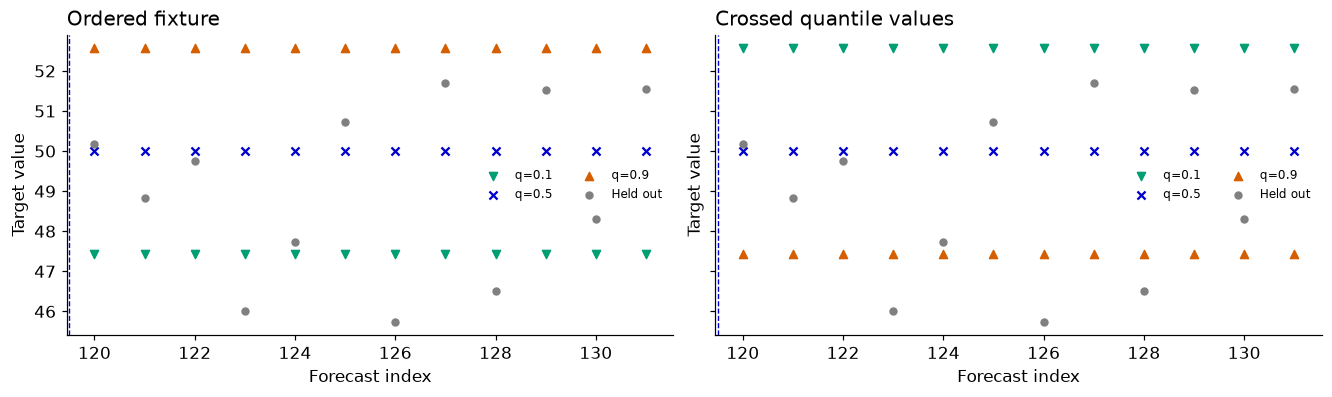

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True, layout='constrained')
quantile_styles = [('#009E73', 'v'), ('#0000CC', 'x'), ('#D55E00', '^')]
for ax, label, output in zip(axes, ['Ordered fixture', 'Crossed quantile values'],
                           [reference_fixture, malformed['quantile_crossing']]):
    for j, (level, (color, marker)) in enumerate(zip(output.levels, quantile_styles)):
        ax.scatter(output.index, output.quantiles[:, 0, j], marker=marker, s=28,
                   color=color, label=f'q={level:.1f}')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=20,
               color='0.5', label='Held out', zorder=5)
    ax.axvline(case.task.future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=label, xlabel='Forecast index', ylabel='Target value')
    ax.legend(fontsize=8, ncol=2)
plt.show()

The crossed output still contains finite numbers, but its probability labels are wrong. A valid zero forecast has a different problem: poor location, recorded as a loss rather than an invented universal failure threshold. A point-only output leaves uncertainty checks unsupported; an unavailable model records an execution error.

In [5]:
weak = Forecast(index=case.task.future_index.copy(),
                point=np.zeros_like(reference_fixture.point),
                target_names=case.task.target_names)
weak_result = evaluate_forecast(case, weak)
assert weak.validate(case.task) == []
assert not any(d.status in {'FAIL', 'ERROR'} for d in weak_result.diagnostics)
display(pd.Series(weak_result.metrics, name='Valid but weak forecast'))
display(diagnostics_table(weak_result))

class DeliberatelyUnavailableModel:
    def fit(self, context):
        raise RuntimeError('Demonstration: a required fitted component is unavailable')

error_report = Pipeline(model_factory=DeliberatelyUnavailableModel).test([scenario], seeds=[7])
execution_error = error_report.cases[0].diagnostics[0]
assert execution_error.status == 'ERROR'
display(pd.DataFrame([{'status': execution_error.status,
                       'exception_type': execution_error.evidence['exception_type'],
                       'exception_message': execution_error.evidence['exception_message']}]))


mse                   2409.913807
mae                     49.045922
mase                    24.204995
mean_reference_mse    2500.000000
Name: Valid but weak forecast, dtype: float64

,check,status,category,message
0,forecast_contract,PASS,correctness,"Forecast indices, target order, shapes, finite..."
1,point_accuracy,INCONCLUSIVE,capability,Point scores are descriptive; no capability ac...
2,quantile_accuracy,UNSUPPORTED,capability,No explicit quantile forecasts were supplied.
3,sample_scores,UNSUPPORTED,capability,No joint predictive samples were supplied.


,status,exception_type,exception_message
0,ERROR,RuntimeError,Demonstration: a required fitted component is ...


## Forget to restore target units

This forecaster predicts a mean in standardized coordinates. The broken branch returns that value directly; the repair applies `z * scale + location`. Shapes and finiteness cannot detect the missing inverse transform. For this estimator, the repaired result must equal the historical mean.

In [6]:
class StandardizedMeanForecaster:
    def __init__(self, restore_units=True):
        self.restore_units = restore_units

    def clone_unfitted(self):
        return type(self)(restore_units=self.restore_units)

    def fit(self, context):
        values = context.to_numpy(dtype=float)
        self.location_ = values.mean(axis=0)
        raw_scale = values.std(axis=0)
        self.scale_ = np.where(raw_scale > 0, raw_scale, 1.0)
        standardized = (values - self.location_) / self.scale_
        self.standardized_mean_ = standardized.mean(axis=0)
        self.names_ = tuple(context.columns)
        return self

    def predict(self, future_index):
        prediction = self.standardized_mean_.copy()
        if self.restore_units:
            prediction = prediction * self.scale_ + self.location_
        return Forecast(index=future_index.copy(),
                        point=np.tile(prediction, (len(future_index), 1)),
                        target_names=self.names_)


In [7]:
broken_template = StandardizedMeanForecaster(restore_units=False)
repaired_template = StandardizedMeanForecaster(restore_units=True)
broken_pipeline = Pipeline(broken_template)
repaired_pipeline = Pipeline(repaired_template)
outputs = {name: pipeline.predict(case.task.context, case.task.future_index)
           for name, pipeline in [('Missing inverse transform', broken_pipeline),
                                  ('Restored target units', repaired_pipeline)]}
repair_results = {name: evaluate_forecast(case, forecast)
                  for name, forecast in outputs.items()}
for forecast in outputs.values():
    assert forecast.validate(case.task) == []
expected_mean = np.tile(case.task.context.mean().to_numpy(), (scenario.horizon, 1))
np.testing.assert_allclose(outputs['Restored target units'].point, expected_mean)
assert not hasattr(broken_template, 'location_')
assert not hasattr(repaired_template, 'location_')
display(pd.DataFrame({name: result.metrics for name, result in repair_results.items()}).T)


,mse,mae,mase,mean_reference_mse
Missing inverse transform,2409.913807,49.045922,24.204995,2500.000000
Restored target units,4.848563,1.859370,0.917630,0.085763


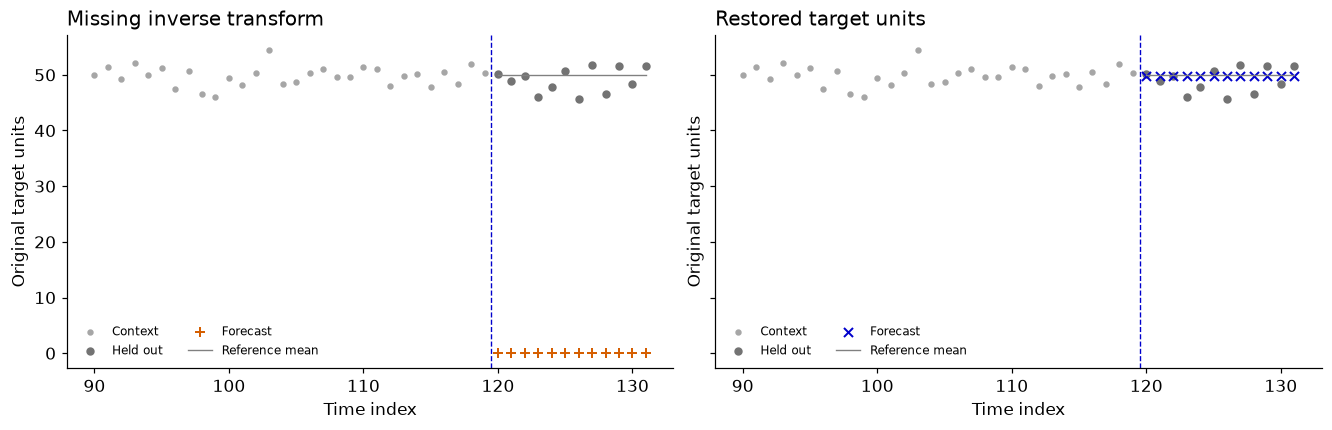

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout='constrained')
for ax, (name, forecast) in zip(axes, outputs.items()):
    ax.scatter(case.task.context.index[-30:], case.task.context.iloc[-30:, 0],
               color='0.65', s=10, label='Context')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], color='0.45', s=20, label='Held out')
    ax.scatter(forecast.index, forecast.point[:, 0], marker='+' if 'Missing' in name else 'x',
               color='#D55E00' if 'Missing' in name else '#0000CC', s=35, linewidths=1.3, label='Forecast')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.5', linewidth=0.9, label='Reference mean')
    ax.axvline(case.task.future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=name, xlabel='Time index', ylabel='Original target units')
    ax.legend(fontsize=8, ncol=2)
plt.show()

The broken points cluster near standardized zero although observations are near 50; the repaired points return to target units. Both outputs satisfy the same structural contract.

## Test the model's promise

A historical mean obeys `f(y + c) = f(y) + c`. This context-only property detects the broken branch. Apply it only to models that promise shift equivariance; clipping or absolute thresholds may intentionally violate it.

In [9]:
shift_checks = {name: check_shift_equivariance(pipeline, case.task.context,
                                              case.task.future_index, shift=10.0)
                for name, pipeline in [('Missing inverse transform', broken_pipeline),
                                       ('Restored target units', repaired_pipeline)]}
assert shift_checks['Missing inverse transform'].status == 'FAIL'
assert shift_checks['Restored target units'].status == 'PASS'
display(pd.DataFrame([{'implementation': name, 'status': d.status, **d.evidence}
                      for name, d in shift_checks.items()]))


,implementation,status,shift,max_absolute_error,atol,rtol
0,Missing inverse transform,FAIL,10.0,10.0,1.000000e-08,1.000000e-07
1,Restored target units,PASS,10.0,0.0,1.000000e-08,1.000000e-07


## Fit fresh objects

A factory must return a new unfitted object for every prediction call. Retain the two instances here to check that shifted contexts fit separately and move the forecast by the same amount.

In [10]:
constructed = []

def model_factory():
    model = StandardizedMeanForecaster(restore_units=True)
    constructed.append(model)
    return model

factory_pipeline = Pipeline(model_factory=model_factory)
first = factory_pipeline.predict(case.task.context, case.task.future_index)
second = factory_pipeline.predict(case.task.context + 10.0, case.task.future_index)
assert len(constructed) == 2 and constructed[0] is not constructed[1]
np.testing.assert_allclose(second.point, first.point + 10.0)
display(pd.DataFrame({'fit_call': [1, 2],
                      'fitted_location': [model.location_[0] for model in constructed]}))


,fit_call,fitted_location
0,1,49.707147
1,2,59.707147


## Save and replay the evidence

The report records scenario seeds, parameters, model settings, dependencies, and source digest. Replay reconstructs allowlisted built-in models; JSON never executes a custom factory. The temporary round-trip checks metric, diagnostic, and manifest equality and reports environment agreement. Exact equality across environments is not promised.

In [11]:
replay_scenario = Scenario('ar1', context_length=100, horizon=6,
                           parameters={'mean': 3.0, 'phi': 0.65, 'sigma': 0.7})
replay_pipeline = Pipeline(GaussianAR1Forecaster(n_samples=96, seed=23))
saved_report = replay_pipeline.test([replay_scenario], seeds=[7, 11],
                                    check_dependence=False)
with TemporaryDirectory(prefix='timegym-notebook-') as directory:
    report_path = Path(directory) / 'report.json'
    saved_report.to_json(report_path)
    loaded_report = json.loads(report_path.read_text(encoding='utf-8'))
    replayed = [replay_case(loaded_report, case_index=i)
                for i in range(len(saved_report.cases))]
comparisons = pd.DataFrame([r.metadata['replay'] for r in replayed])
assert comparisons[['metrics_match', 'diagnostics_match', 'manifest_match']].all().all()
display(comparisons)
print('Report schema:', loaded_report['schema_version'])
print('JSON pipeline configuration:')
print(json.dumps(loaded_report['metadata']['pipeline_config'], indent=2))


,case_index,metrics_match,diagnostics_match,manifest_match,source_matches,dependencies_match,python_matches
0,0,True,True,True,True,True,True
1,1,True,True,True,True,True,True


Report schema: 2.0
JSON pipeline configuration:
{
  "model": {
    "class": "GaussianAR1Forecaster",
    "kind": "builtin",
    "parameters": {
      "n_samples": 96,
      "seed": 23
    }
  },
  "replayable": true,
  "schema_version": 1,
  "strategy": "recursive",
  "window_length": 12
}


## Retain custom model source

The custom forecaster's JSON records provenance but cannot reproduce its executable implementation. Safe replay therefore refuses it; retain this notebook, constructor settings, seeds, and environment.

In [12]:
custom_report = repaired_pipeline.test([scenario], seeds=[7])
assert custom_report.metadata['pipeline_config']['replayable'] is False
try:
    replay_case(custom_report)
except ValueError as exc:
    custom_replay_outcome = {'exception': type(exc).__name__, 'message': str(exc)}
else:
    raise AssertionError('Custom code must not become executable through report JSON.')
display(pd.DataFrame([custom_replay_outcome]))


,exception,message
0,ValueError,This model configuration is not automatically ...


## Use the same reasoning on a new fault

Preserve a minimal failure, inspect its output, declare a property the model promises, repair the implementation, and repeat the comparison. Try changing the scenario mean and scale while leaving the inverse-transform fault intact.

**Scope.** `assert_passed()` rejects `FAIL`/`ERROR` without turning unsupported or inconclusive checks into evidence of skill. Statistical checks can reject clean forecasts at their declared level; this replay example leaves the covariance test disabled. A good score on one future path does not prove calibration, and a failed property does not uniquely identify its cause.

Continue with [real-data forecasts](24_real_data_forecasts.ipynb).